# CO2 Emissions Regression

Simple and multiple linear regression to predict vehicle CO2 emissions from engine size and fuel consumption (FuelConsumptionCo2 dataset).


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [7]:
url= "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%202/data/FuelConsumptionCo2.csv"

In [8]:
df=pd.read_csv(url)

In [9]:
# verify successful load with some randomly selected records
df.sample(5)

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
67,2014,AUDI,TTS ROADSTER QUATTRO,TWO-SEATER,2.0,4,A6,Z,11.5,8.8,10.3,27,237
131,2014,BMW,X5 xDRIVE50i,SUV - STANDARD,4.4,8,A8,Z,16.3,10.9,13.9,20,320
5,2014,ACURA,RLX,MID-SIZE,3.5,6,AS6,Z,11.9,7.7,10.0,28,230
1050,2014,VOLKSWAGEN,ROUTAN,MINIVAN,3.6,6,A6,X,14.2,9.5,12.1,23,278
862,2014,NISSAN,VERSA,COMPACT,1.6,4,M5,X,8.6,6.5,7.7,37,177


In [10]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [11]:
cdf = df[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
cdf.sample(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
800,1.6,4,9.0,207
143,1.4,4,9.2,212
580,2.4,4,9.4,216
34,4.0,8,12.5,288
535,3.7,6,11.0,253
956,2.5,4,9.9,228
427,3.5,6,15.7,251
2,1.5,4,5.9,136
403,2.0,4,7.8,179


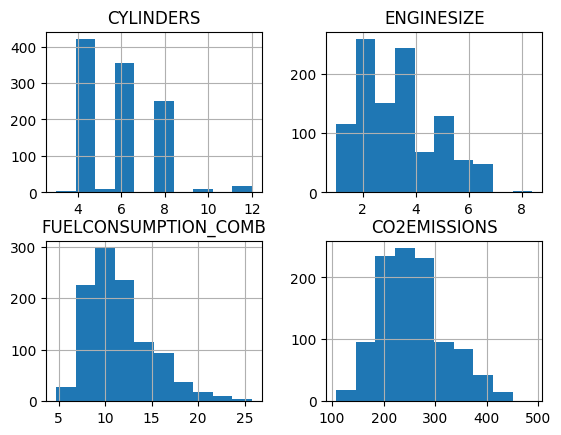

In [12]:
viz = cdf[['CYLINDERS','ENGINESIZE','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
viz.hist()
plt.show()

CYLINDERS: Shows a discrete, multimodal distribution concentrated in even cylinder counts (4, 6, and 8). 4-cylinder engines represent the absolute mode of the dataset with over 400 records, reflecting a strong dominance of smaller, fuel-efficient engines.   ENGINESIZE: Exhibits a right-skewed distribution, with the vast majority of vehicles clustered between 2.0 L and 3.5 L displacement. Large engines (> 5.0 L) are far less common and represent high-displacement outliers within the sample.   FUELCONSUMPTION_COMB: Displays positive skewness with a central concentration between 8 and 12 L/100 km. The right tail highlights a small proportion of high-consumption vehicles reaching up to 25 L/100 km.   CO2EMISSIONS: Features an approximately normal distribution (slightly skewed to the right) with a clear central peak, where most vehicles emit between 200 and 300 g/km of CO2. Its structural similarity to the fuel consumption distribution reflects a strong direct correlation between fuel burn and carbon emissions. 

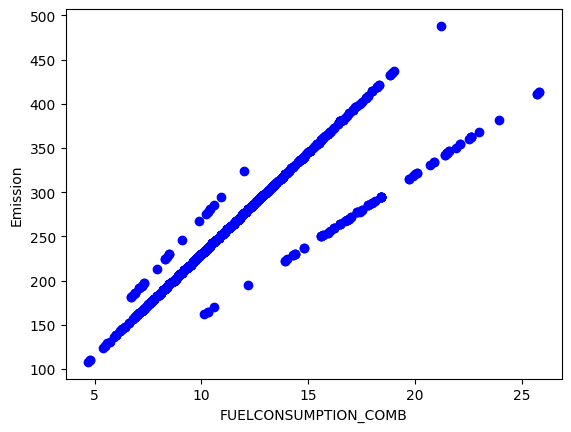

In [13]:
plt.scatter(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("FUELCONSUMPTION_COMB")
plt.ylabel("Emission")
plt.show()

Strong Linear Correlation: There is a strong direct linear relationship between combined fuel consumption (FUELCONSUMPTION_COMB) and CO2 emissions (Emission). Higher fuel consumption consistently results in higher emissions.   Parallel Subgroups (Categorical Clustering): The data splits into two main parallel linear tracks. This behavior strongly suggests the presence of an underlying categorical variable, such as Fuel Type (e.g., gasoline vs. diesel vs. ethanol/E85), as different fuels produce varying CO2 outputs per liter consumed.   Presence of Outliers: A few isolated data points lie outside the main linear trends (e.g., around 21 L/100 km emitting near 490 g/km, or 12 L/100 km emitting near 325 g/km).   Predictive Modeling Potential: The clear linear structure indicates that regression models (especially multiple linear regression incorporating fuel type) will yield a very high coefficient of determination ($R^2$) for predicting emissions.  

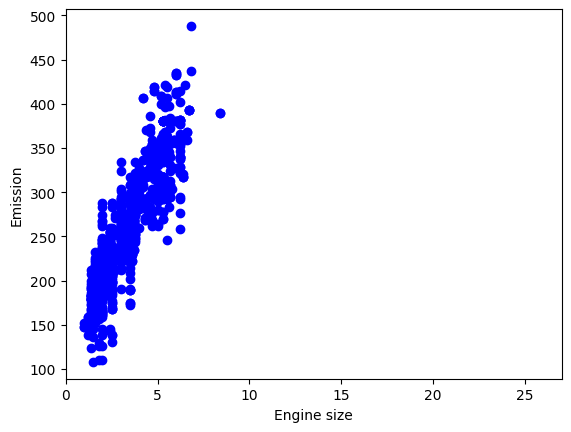

In [14]:
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.xlim(0,27)
plt.show()

Positive Non-Linear / Curved Trend: Displays a clear positive association where larger engine sizes generally correspond to higher CO2 emissions, but the relationship shows a slight upward curve (polynomial behavior) rather than a strictly linear pattern.   High Variance at Medium-to-High Displacement: As engine size increases (particularly between 3.0 L and 6.0 L), the spread of emission values widens significantly. This variance indicates that engine size alone does not determine emissions; factors like vehicle weight, fuel type, and induction (turbocharged vs. naturally aspirated) play key roles.   Concentration in Low-Displacement Segment: The highest density of data points is clustered below 3.5 L with emissions ranging from 100 to 300 g/km, reflecting the standard consumer vehicle market.   Extreme Outliers: Notable outliers appear at the upper end of displacement and emissions (e.g., engine size around 6.8 L pushing near 490 g/km in emissions).   Modeling Implications: Polynomial regression (e.g., degree 2) or a multiple linear regression incorporating additional variables (such as fuel consumption or cylinders) will outperform a simple linear fit for predicting emissions based on engine size. 

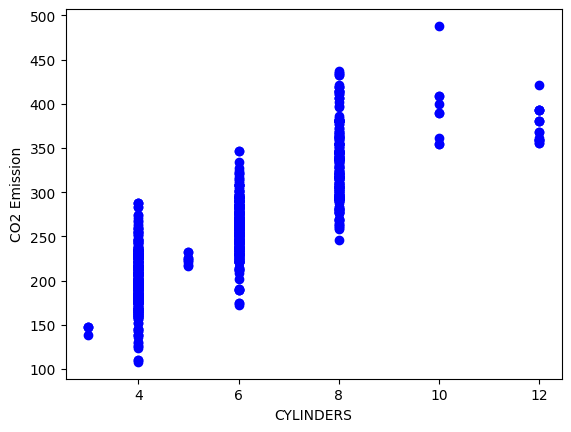

In [15]:
plt.scatter(cdf.CYLINDERS, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("CYLINDERS")
plt.ylabel("CO2 Emission")
plt.show()

Positive Stepwise / Grouped Trend: Demonstrates a clear upward progression where higher cylinder counts correspond to increased average $CO_2$ emissions.   Discrete Category Clustering: Because CYLINDERS is a discrete integer variable, data points align in vertical strips at specific cylinder values (3, 4, 5, 6, 8, 10, and 12).   High Concentration in Standard Engine Configurations: The vast majority of vehicles cluster around 4, 6, and 8 cylinders:   4 Cylinders: Lowest average emissions, ranging primarily from 110 to 290 g/km.   6 Cylinders: Mid-tier emissions, ranging between 175 and 350 g/km.   8 Cylinders: High-tier emissions, spanning from 250 up to 440 g/km.   Vertical Dispersion Within Clusters: Significant vertical variation exists within each cylinder group (e.g., 8-cylinder vehicles show a ~190 g/km spread). This indicates that engine size, vehicle weight, and fuel efficiency strongly influence emissions beyond cylinder count alone.   Rare Engine Outliers: Rare configurations—such as 3-cylinder, 5-cylinder, 10-cylinder, and 12-cylinder engines—have very low sample counts. Notably, a 10-cylinder vehicle records the peak emission value of nearly 490 g/km. 

In [16]:
X = cdf.ENGINESIZE.to_numpy()
y = cdf.CO2EMISSIONS.to_numpy()

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [18]:
type(X_train), np.shape(X_train), np.shape(X_train)

(numpy.ndarray, (853,), (853,))

In [19]:
from sklearn import linear_model

# create a model object
regressor = linear_model.LinearRegression()

# train the model on the training data
# X_train is a 1-D array but sklearn models expect a 2D array as input for the training data, with shape (n_observations, n_features).
# So we need to reshape it. We can let it infer the number of observations using '-1'.
regressor.fit(X_train.reshape(-1, 1), y_train)

# Print the coefficients
print ('Coefficients: ', regressor.coef_[0]) # with simple linear regression there is only one coefficient, here we extract it from the 1 by 1 array.
print ('Intercept: ',regressor.intercept_)

# Predict on the test data
y_pred = regressor.predict(X_test.reshape(-1, 1))

# Evaluate the model
from sklearn.metrics import mean_squared_error, r2_score
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("Coefficient of determination (R^2): %.2f" % r2_score(y_test, y_pred))

Coefficients:  38.992978724434074
Intercept:  126.28970217408721
Mean squared error: 985.94
Coefficient of determination (R^2): 0.76


Text(0, 0.5, 'Emission')

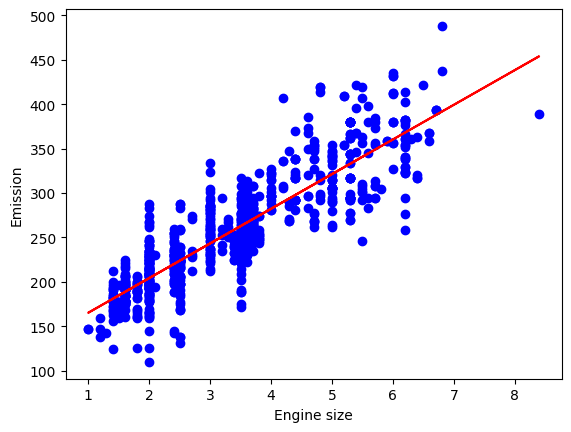

In [20]:
plt.scatter(X_train, y_train,  color='blue')
plt.plot(X_train, regressor.coef_ * X_train + regressor.intercept_, '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")

Positive Linear Trend Line: The fitted red regression line captures a clear positive linear relationship, showing that predicted $\text{CO}_2$ emissions increase monotonically as Engine size increases.   Baseline and Slope: The regression line starts at an emission value near ~165 g/km for a 1.0 L engine and extends up to approximately ~450 g/km for an 8.4 L engine. This indicates a substantial positive slope coefficient ($\theta_1 > 0$).   Residual Variance (Goodness of Fit): While the line tracks the central tendency well, points are moderately spread around the line—especially between 3.5 L and 6.5 L. This spread reflects non-zero residuals, demonstrating that a simple linear model captures the general trend but leaves unexplained variance due to omitted factors (e.g., fuel type, vehicle weight).   Slight Non-Linearity / Underfitting: The actual data exhibits a subtle upward curvature at higher displacement levels, causing the straight red line to slightly overestimate emissions for small engines (~2.0 L to 3.0 L) and underestimate extreme high-displacement values.   Model Benchmark: This simple linear regression provides a solid baseline model, though incorporating additional predictors (multiple linear regression) or polynomial terms (polynomial regression) would improve accuracy and lower overall prediction error. 

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the predict method to make test predictions
y_pred = regressor.predict(X_test.reshape(-1,1))

# Evaluation
print("Mean absolute error: %.2f" % mean_absolute_error(y_test, y_pred))
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("Root mean squared error: %.2f" % np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2-score: %.2f" % r2_score(y_test, y_pred))

Mean absolute error: 24.10
Mean squared error: 985.94
Root mean squared error: 31.40
R2-score: 0.76


Mean Absolute Error (MAE = 24.10): On average, the model's predictions deviate from actual $\text{CO}_2$ emissions by approximately 24.10 g/km. This provides a direct, intuitive measure of average prediction error.   Mean Squared Error (MSE = 985.94): Represents the variance of the residuals ($\text{g/km}^2$). Because errors are squared before averaging, this higher value penalizes larger errors and outliers in the dataset.   Root Mean Squared Error (RMSE = 31.40): Returning the squared error metric back to original units ($\text{g/km}$), the average standard deviation of the residuals is 31.40 g/km. The gap between RMSE ($31.40$) and MAE ($24.10$) confirms the presence of some larger prediction errors/outliers in the test set.   R²-Score (0.76): The model explains 76% of the total variance in $\text{CO}_2$ emissions using engine size alone. While 0.76 indicates a strong linear fit, the remaining 24% of unexplained variance leaves clear room for improvement.   Overall Takeaway: Simple linear regression produces a solid baseline model. However, to capture the remaining 24% of variance, upgrading to Multiple Linear Regression (adding features like FUELCONSUMPTION_COMB and CYLINDERS) or Polynomial Regression would significantly reduce error metrics and improve predictive accuracy.  

Text(0, 0.5, 'Emission')

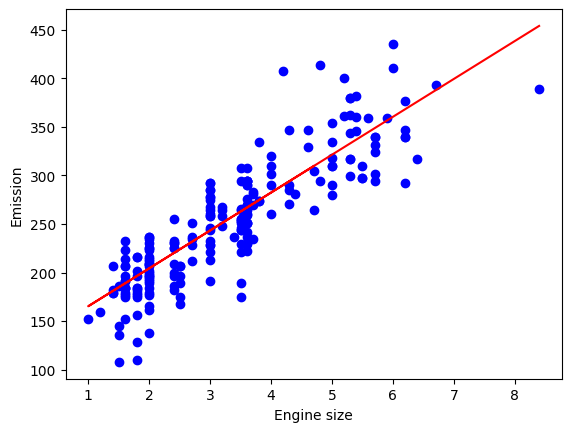

In [22]:
plt.scatter(X_test, y_test,  color='blue')
plt.plot(X_test, regressor.coef_ * X_test + regressor.intercept_, '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")

Fitted Linear Fit: The red regression line illustrates the trained linear model's predicted output ($\hat{y}$) plotted against Engine size. It illustrates a constant rate of increase in emissions as displacement grows.   Alignment with Central Distribution: The regression line cuts through the dense center of the scatter plot, successfully capturing the main linear tendency across the 1.0 L to 8.4 L engine range.   Residual Spread Across Displacements:Low Displacement (1.0 L – 3.0 L): Data points cluster tightly around the line, though the linear model slightly overestimates emissions for small engines below 2.0 L.   Mid-to-High Displacement (3.5 L – 6.5 L): Vertical dispersion increases significantly around the red line, demonstrating higher prediction variance where additional features (such as fuel type or vehicle weight) are needed.   Polynomial Tendency: The slight upward curvature of the actual data points relative to the straight red line confirms that a degree-2 polynomial regression would provide a closer fit than this straight linear boundary.   

In [23]:
# Drop categoricals and any unseless columns
df = df.drop(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'TRANSMISSION', 'FUELTYPE',],axis=1)

In [24]:
df.corr()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
ENGINESIZE,1.000000,0.934011,0.832225,0.778746,0.819482,-0.808554,0.874154
CYLINDERS,0.934011,1.000000,0.796473,0.724594,0.776788,-0.770430,0.849685
FUELCONSUMPTION_CITY,0.832225,0.796473,1.000000,0.965718,0.995542,-0.935613,0.898039
FUELCONSUMPTION_HWY,0.778746,0.724594,0.965718,1.000000,0.985804,-0.893809,0.861748
FUELCONSUMPTION_COMB,0.819482,0.776788,0.995542,0.985804,1.000000,-0.927965,0.892129
FUELCONSUMPTION_COMB_MPG,-0.808554,-0.770430,-0.935613,-0.893809,-0.927965,1.000000,-0.906394
CO2EMISSIONS,0.874154,0.849685,0.898039,0.861748,0.892129,-0.906394,1.000000


In [25]:
df = df.drop(['CYLINDERS', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY','FUELCONSUMPTION_COMB',],axis=1)

In [26]:
df.head(9)

,ENGINESIZE,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2.0,33,196
1,2.4,29,221
2,1.5,48,136
3,3.5,25,255
4,3.5,27,244
5,3.5,28,230
6,3.5,28,232
7,3.7,25,255
8,3.7,24,267


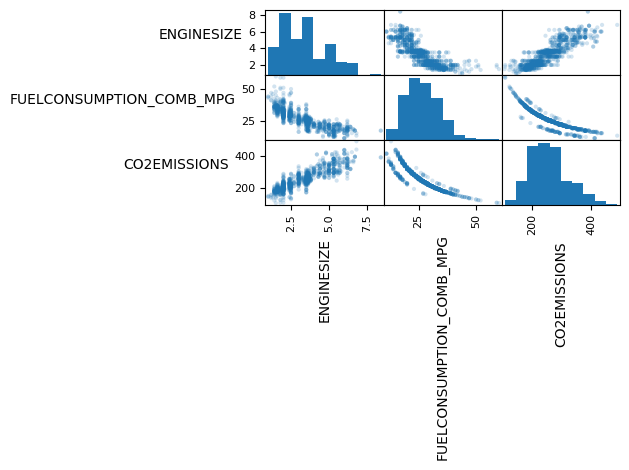

In [27]:
axes = pd.plotting.scatter_matrix(df, alpha=0.2)
# need to rotate axis labels so we can read them
for ax in axes.flatten():
    ax.xaxis.label.set_rotation(90)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_ha('right')

plt.tight_layout()
plt.gcf().subplots_adjust(wspace=0, hspace=0)
plt.show()

Diagonal Histograms (Univariate Distributions):ENGINESIZE: Right-skewed distribution centered predominantly around 2.0 L to 3.5 L.   FUELCONSUMPTION_COMB_MPG: Right-skewed distribution peaked around 25 MPG, with a long tail extending toward higher efficiency (>40 MPG).   CO2EMISSIONS: Approximately normal distribution centered between 200 and 300 g/km.   Inverse Non-Linear Relationship (MPG vs. Engine Size & CO2):ENGINESIZE vs. FUELCONSUMPTION_COMB_MPG: Shows a strong inverse, non-linear (hyperbolic) decay. As engine displacement increases, fuel efficiency in miles per gallon drops rapidly before leveling off around 15–20 MPG.   FUELCONSUMPTION_COMB_MPG vs. CO2EMISSIONS: Displays a sharp non-linear reciprocal curve ($\text{CO}_2 \propto \frac{1}{\text{MPG}}$). Higher MPG ratings lead to dramatically lower emissions, leveling off as fuel economy increases.   Positive Direct Relationship (ENGINESIZE vs. CO2EMISSIONS):Displays a positive trend where higher displacement increases carbon output, showing increasing variance in emissions at larger engine sizes (3.5 L to 6.5 L).

In [28]:
X = df.iloc[:,[0,1]].to_numpy()
y = df.iloc[:,[2]].to_numpy()

In [29]:
from sklearn import preprocessing

std_scaler = preprocessing.StandardScaler()
X_std = std_scaler.fit_transform(X)

In [30]:
pd.DataFrame(X_std).describe().round(2)

,0,1
count,1067.00,1067.00
mean,0.00,-0.00
std,1.00,1.00
min,-1.66,-2.07
25%,-0.95,-0.73
50%,0.04,-0.06
75%,0.67,0.61
max,3.57,4.50


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_std,y,test_size=0.2,random_state=42)

In [32]:
from sklearn import linear_model

# create a model object
regressor = linear_model.LinearRegression()

# train the model in the training data
regressor.fit(X_train, y_train)

# Print the coefficients
coef_ =  regressor.coef_
intercept_ = regressor.intercept_

print ('Coefficients: ',coef_)
print ('Intercept: ',intercept_)


Coefficients:  [[ 25.27339614 -37.4381472 ]]
Intercept:  [256.29072488]


In [33]:
# Get the standard scaler's mean and standard deviation parameters
means_ = std_scaler.mean_
std_devs_ = np.sqrt(std_scaler.var_)

# The least squares parameters can be calculated relative to the original, unstandardized feature space as:
coef_original = coef_ / std_devs_
intercept_original = intercept_ - np.sum((means_ * coef_) / std_devs_)

print ('Coefficients: ', coef_original)
print ('Intercept: ', intercept_original)


Coefficients:  [[17.8581369  -5.01502179]]
Intercept:  [329.1363967]


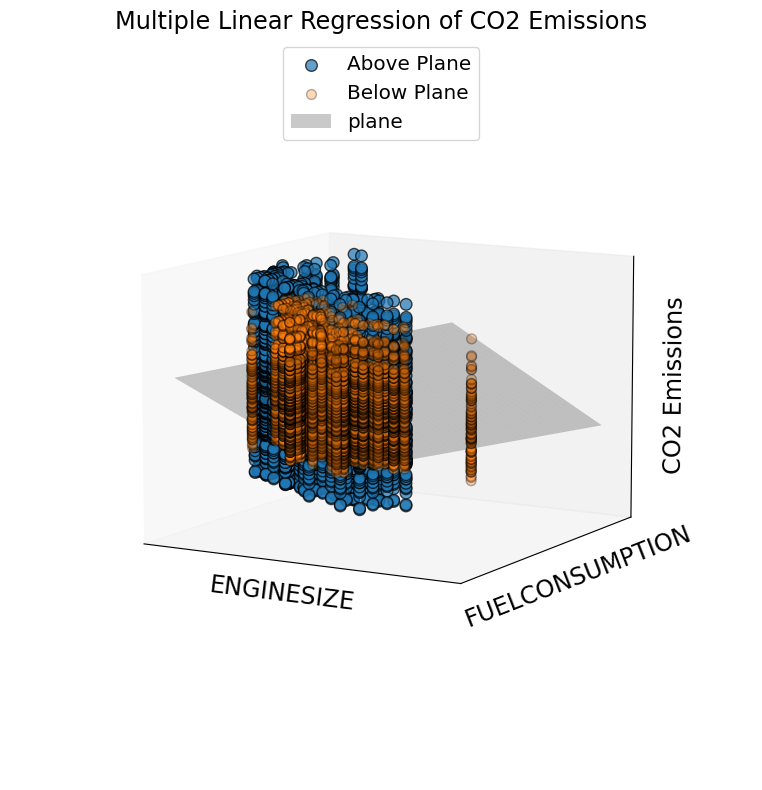

In [34]:
#from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import matplotlib.pyplot as plt

# Ensure X1, X2, and y_test have compatible shapes for 3D plotting
X1 = X_test[:, 0] if X_test.ndim > 1 else X_test
X2 = X_test[:, 1] if X_test.ndim > 1 else np.zeros_like(X1)

# Create a mesh grid for plotting the regression plane
x1_surf, x2_surf = np.meshgrid(np.linspace(X1.min(), X1.max(), 100), 
                               np.linspace(X2.min(), X2.max(), 100))

y_surf = intercept_ +  coef_[0,0] * x1_surf  +  coef_[0,1] * x2_surf

# Predict y values using trained regression model to compare with actual y_test for above/below plane colors
y_pred = regressor.predict(X_test.reshape(-1, 1)) if X_test.ndim == 1 else regressor.predict(X_test)
above_plane = y_test >= y_pred
below_plane = y_test < y_pred
above_plane = above_plane[:,0]
below_plane = below_plane[:,0]

# Plotting
fig = plt.figure(figsize=(20, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the data points above and below the plane in different colors
ax.scatter(X1[above_plane], X2[above_plane], y_test[above_plane],  label="Above Plane",s=70,alpha=.7,ec='k')
ax.scatter(X1[below_plane], X2[below_plane], y_test[below_plane],  label="Below Plane",s=50,alpha=.3,ec='k')

# Plot the regression plane
ax.plot_surface(x1_surf, x2_surf, y_surf, color='k', alpha=0.21,label='plane')

# Set view and labels
ax.view_init(elev=10)

ax.legend(fontsize='x-large',loc='upper center')
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
ax.set_box_aspect(None, zoom=0.75)
ax.set_xlabel('ENGINESIZE', fontsize='xx-large')
ax.set_ylabel('FUELCONSUMPTION', fontsize='xx-large')
ax.set_zlabel('CO2 Emissions', fontsize='xx-large')
ax.set_title('Multiple Linear Regression of CO2 Emissions', fontsize='xx-large')
plt.tight_layout()
plt.show()


Multiple Linear Regression Plane ConclusionsHyperplane Fitting in 3D Space: The grey 2D plane represents the fitted Multiple Linear Regression model equation: $\hat{y} = \theta_0 + \theta_1 \cdot \text{ENGINESIZE} + \theta_2 \cdot \text{FUELCONSUMPTION}$. It predicts $CO_2$ emissions using two predictor variables simultaneously.   3D Residual Classification: Data points are color-coded based on their position relative to the regression plane:   Blue Points (Above Plane): Represent positive residuals ($y_i - \hat{y}_i > 0$), where actual emissions exceed the model's estimate.   Orange Points (Below Plane): Represent negative residuals ($y_i - \hat{y}_i < 0$), where actual emissions fall below predicted values.   Multivariate Gradient: The sloped tilt of the grey plane visually confirms that $CO_2$ emissions increase monotonically as both ENGINESIZE and FUELCONSUMPTION grow.   

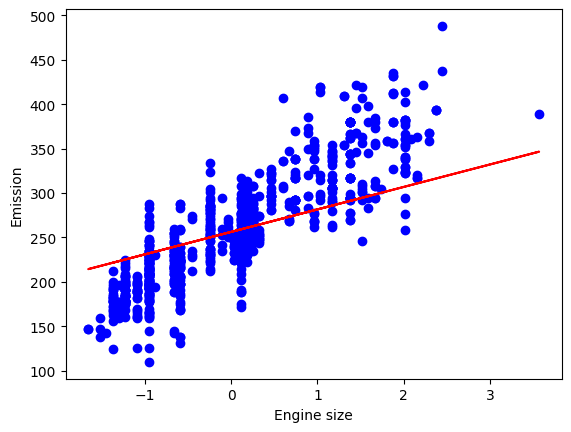

In [35]:
plt.scatter(X_train[:,0], y_train,  color='blue')
plt.plot(X_train[:,0], coef_[0,0] * X_train[:,0] + intercept_[0], '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.show()

Standardized Feature Scaling (Z-Score Standardization): The x-axis (Engine size) has been scaled to a mean of $0$ and a standard deviation of $1$ (ranging roughly from $-1.8$ to $+3.6$). This preprocessing step preserves the underlying relationship while ensuring balanced gradient steps during optimization algorithms like Gradient Descent.   Shifted Y-Intercept ($\theta_0$): In standardized space, the red regression line crosses the y-axis (at $x = 0$, representing the mean engine size) around an emission value of $\sim 260\text{ g/km}$. This intercept corresponds directly to the expected emission for an average-sized engine in the dataset.   Positive Trend & Sub-optimal Fit: The fitted line demonstrates a positive slope, confirming that engine sizes above average ($x > 0$) predict higher-than-average emissions. However, the line appears flatter than the unstandardized fit (underfitting), systematically overestimating emissions for smaller engines ($x < 0$) and underestimating emissions for larger engines ($x > 1.5$).

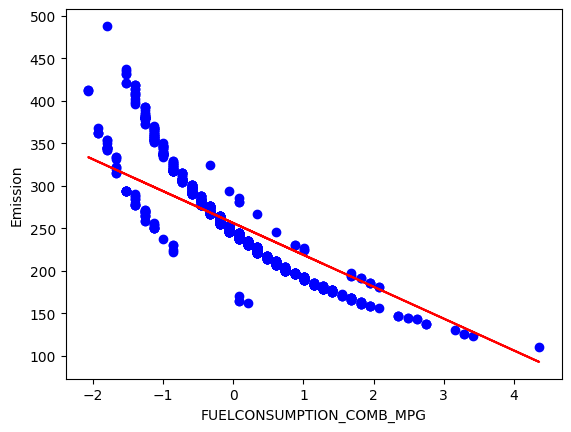

In [36]:
plt.scatter(X_train[:,1], y_train,  color='blue')
plt.plot(X_train[:,1], coef_[0,1] * X_train[:,1] + intercept_[0], '-r')
plt.xlabel("FUELCONSUMPTION_COMB_MPG")
plt.ylabel("Emission")
plt.show()

Standardized Inverse Relationship: The x-axis (FUELCONSUMPTION_COMB_MPG) has been standardized using Z-score scaling (centered at $0$, representing the mean fuel efficiency in MPG). The downward slope confirms that above-average fuel efficiency ($x > 0$) corresponds to significantly lower $\text{CO}_2$ emissions.   Negative Linear Fit Misalignment: A standard straight red regression line attempts to fit the data, but it struggles to capture the non-linear structure. Because the true relationship between MPG and emissions is non-linear (reciprocal/curved), a linear line underestimates emissions at the low-efficiency extreme ($x < -1$) and overestimates emissions in the mid-range ($x \approx 0$ to $2$).   Parallel Sub-Curves (Fuel Types): The scatter plot reveals two distinct curved parallel bands rather than a single cluster. This visual separation further highlights that fuel type (e.g., gasoline vs. ethanol/E85) plays a critical role in determining carbon output per mile per gallon.   Transformation & Feature Engineering: To achieve a better fit, the standardized MPG variable should be transformed—either by using a polynomial feature extension, taking the inverse ($\frac{1}{\text{MPG}}$) to convert back to fuel rate, or adding fuel type as a categorical predictor.   

In [37]:
X_train_1 = X_train[:,0]
regressor_1 = linear_model.LinearRegression()
regressor_1.fit(X_train_1.reshape(-1, 1), y_train)
coef_1 =  regressor_1.coef_
intercept_1 = regressor_1.intercept_
print ('Coefficients: ',coef_1)
print ('Intercept: ',intercept_1)

Coefficients:  [[55.18408797]]
Intercept:  [256.77183014]


Text(0, 0.5, 'Emission')

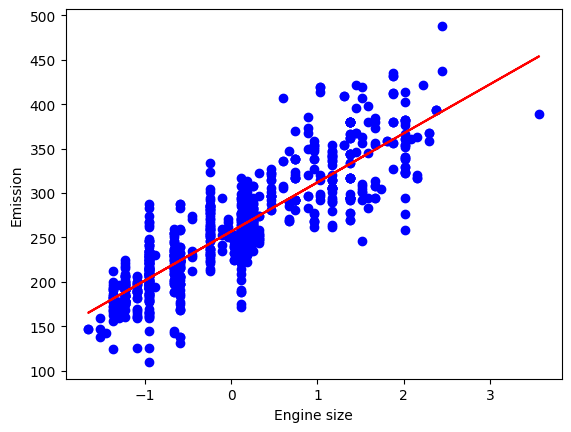

In [38]:
plt.scatter(X_train_1, y_train,  color='blue')
plt.plot(X_train_1, coef_1[0] * X_train_1 + intercept_1, '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")

Text(0, 0.5, 'CO2 Emission')

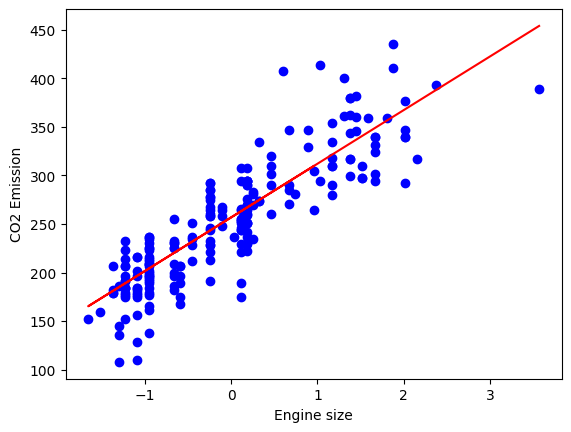

In [39]:
X_test_1 = X_test[:,0]
plt.scatter(X_test_1, y_test,  color='blue')
plt.plot(X_test_1, coef_1[0] * X_test_1 + intercept_1, '-r')
plt.xlabel("Engine size")
plt.ylabel("CO2 Emission")